# EDA_DS2_POS · Retail POS (Dataset 2): data cleaning and graph preparation

**Owner:** Hansen · **Dataset:** [Retail POS on Kaggle](https://www.kaggle.com/datasets/arunsworkspace/retail-pos-dataset-for-market-basket-analysis) · **Needs:** pandas, numpy, matplotlib, networkx and `kagglehub` (downloads the CSV in Section 1)

| Question | Where to read |
|---|---|
| What needs cleaning? | Sections 1-2 |
| Do customers return across months? | Section 3 |
| What are the nodes, edges and relationship strengths? | Sections 4-5 |
| Is this enough data/categories for a GNN? | Sections 6-7 |
| Which predictors and input arrays do we use? | Sections 8-9 |
| How good are the recommendations? | `GCN_DS2_POS.ipynb` |

Section 2 saves `data/retail_cleaned.csv`, the Retail POS input of the team's shared graph pipeline. Sections 3-9 explore our first, product-level graph (68 products). The final models instead rank the 17 categories on the team's shared monthly snapshots; see `GCN_DS2_POS.ipynb`.

## 1. Load and understand one row

A row is a **product line inside an order**, not a whole order or a customer.

| Column | Meaning and use |
|---|---|
| `order_id` | Basket identifier; count distinct orders, not lines |
| `user_id` | Customer identifier; defines customer nodes |
| `order_date`, `time` | Combine into a timestamp for the time split |
| `order_hour_of_day` | Redundant hour; check against the timestamp |
| `product_name` | Product identity after validation |
| `category` | Product category; used for node features |
| `quantity` | Units on this line; not the number of visits |
| `price` | Recorded price; currency/price semantics are not established here |
| `product_id` | Supplied product identifier; we check whether it is consistent |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

import kagglehub

# Download the CSV from Kaggle
file_path = kagglehub.dataset_download(
    "arunsworkspace/retail-pos-dataset-for-market-basket-analysis",
    path="Retail_pos_basket_data.csv.csv"  # Kaggle filename has .csv twice
)

# Load it into a pandas DataFrame
raw = pd.read_csv(file_path)

print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (10000, 10)


,order_id,user_id,order_date,time,order_hour_of_day,product_name,quantity,price,category,product_id
0,1000,341,2024-09-04,15:43:00,15,Wheat Flour,1,333.44,Grains & Staples,457
1,1000,341,2024-09-04,15:43:00,15,Dishwashing Liquid,2,405.92,Household,745
2,1000,341,2024-09-04,15:43:00,15,Pastry,2,114.15,Bakery,849
3,1000,341,2024-09-04,15:43:00,15,Marker,2,171.33,Stationery,599
4,1001,324,2024-03-07,8:45:00,8,Saree,2,41.16,Clothing,329


In [2]:
raw.info()

print("------------------------------- Data Summary -----------------------------")
display(pd.DataFrame({"unique_values": raw.nunique(), "missing": raw.isna().sum()}))
print("Exact duplicate rows:", raw.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   order_id           10000 non-null  int64  
 1   user_id            10000 non-null  int64  
 2   order_date         10000 non-null  str    
 3   time               10000 non-null  str    
 4   order_hour_of_day  10000 non-null  int64  
 5   product_name       10000 non-null  str    
 6   quantity           10000 non-null  int64  
 7   price              10000 non-null  float64
 8   category           10000 non-null  str    
 9   product_id         10000 non-null  int64  
dtypes: float64(1), int64(5), str(4)
memory usage: 781.4 KB
------------------------------- Data Summary -----------------------------


,unique_values,missing
order_id,1991,0
user_id,488,0
order_date,363,0
time,896,0
order_hour_of_day,17,0
product_name,68,0
quantity,3,0
price,9083,0
category,17,0
product_id,900,0


Exact duplicate rows: 0


**Result:** there are **10,000 product lines, 1,991 orders and 488 customers**. There are 68 product names but 900 product IDs, which needs investigation (Section 2). The supplied CSV has no missing values or exact duplicate rows.

## 2. Clean values

Strip accidental text spaces, remove exact duplicate rows, and parse timestamps. We stop on invalid essential values rather than silently inventing replacements. Large values are not automatically errors.

In [3]:
df = raw.copy()
for column in ["product_name", "category"]:
    df[column] = df[column].str.strip()
df = df.drop_duplicates().reset_index(drop=True)

df["timestamp"] = pd.to_datetime(df["order_date"] + " " + df["time"], errors="coerce")

# If any of these columns have missing values, raise an error
assert df[["order_id", "user_id", "product_name", "category", "timestamp"]].notna().all().all()
assert df[["product_name", "category"]].ne("").all().all()
assert df["timestamp"].dt.year.eq(2024).all(), "Review the time split for a different year."

print("Rows retained:", len(df))
print("Date range:", df["timestamp"].min(), "to", df["timestamp"].max())

Rows retained: 10000
Date range: 2024-01-01 06:23:00 to 2024-12-31 21:33:00


In [4]:
display(df[["quantity", "price"]].describe().round(2))

assert (df[["quantity", "price"]] > 0).all().all()
assert df["quantity"].mod(1).eq(0).all()
assert df["order_hour_of_day"].eq(df["timestamp"].dt.hour).all()

order_check = df.groupby("order_id")[["user_id", "timestamp"]].nunique()

assert order_check.eq(1).all().all(), "An order must have one customer and timestamp."

print("Order identities and recorded hours are consistent.")

,quantity,price
count,10000.00,10000.00
mean,2.01,255.97
std,0.82,141.30
min,1.00,10.09
25%,1.00,132.96
50%,2.00,257.20
75%,3.00,377.77
max,3.00,499.96


Order identities and recorded hours are consistent.


**Result:** all 10,000 rows remain. Dates cover 2024; quantities are positive integers from 1 to 3, prices are positive, and each order belongs to one customer at one timestamp. These checks establish usable values, not proof that every transaction is realistic.

In [5]:
names_per_id = df.groupby("product_id")["product_name"].nunique()
print("Names per product_id: min =", names_per_id.min(), "; max =", names_per_id.max())
print("IDs linked to multiple names:", names_per_id.gt(1).sum())
display(df.loc[df["product_id"].eq(100), ["product_id", "product_name", "category"]].drop_duplicates())
assert df.groupby("product_name")["category"].nunique().eq(1).all()

Names per product_id: min = 2 ; max = 20
IDs linked to multiple names: 900


,product_id,product_name,category
743,100,Jeans,Clothing
1843,100,Banana,Fruits & Vegetables
2358,100,Shampoo,Personal Care
3081,100,Shoes,Footwear
3934,100,Fish,Meat & Seafood
4012,100,Lentils,Grains & Staples
8748,100,Pasta,Grains & Staples
8758,100,Salt,Grains & Staples


**Decision:** all 900 product IDs map to multiple names (2-20 each), so they cannot identify products. Each product name maps to one category, so use **`product_name` as the product node identity**. These are 68 named products, not verified fine-grained SKUs; variants with the same name would be merged.

`user_id` behaves consistently within orders, but we cannot independently verify real people behind these identifiers.

In [6]:
price_ranges = df.groupby("product_name")["price"].agg(["min", "max", "mean"])
display(price_ranges.head().round(2))
print("Repeated product lines within the same basket:", df.duplicated(["order_id", "product_name"]).sum())
Path("data").mkdir(exist_ok=True)
df.to_csv("data/retail_cleaned.csv", index=False)      # input of the team's shared graph pipeline

,min,max,mean
product_name,,,
Apple,16.85,490.58,251.79
Baby Food,10.37,487.72,250.72
Banana,19.84,498.86,241.51
Beef,10.68,498.13,254.48
Belt,10.92,497.31,265.07


Repeated product lines within the same basket: 299


**Decision:** a single named product has a very wide price range (Apple is about 17-491). Without reliable price semantics, exclude price from the model. This does **not** prove the prices were generated randomly.

There are 299 repeated `(order_id, product_name)` lines. Keep these in the cleaned line-level CSV, but count a product **once per basket** for graph weights and category profiles. Buying three units or appearing on two lines in one basket is not three separate visits.

## 3. Split by time and check returning customers

- **Train:** January-October 2024; build all model inputs from this part.
- **Validation:** November; choose model settings/checkpoints.
- **Test:** December; report performance after choices are fixed.

The prediction unit is **distinct products bought by a customer during a month**, not the next basket or number of units. November and December are both evaluated using the same January-October history. We do not update the graph with November purchases before testing.

Customer overlap is desirable: this is an **existing-customer recommendation** task. Future purchases entering training features would be leakage; the same customer appearing in another month is not leakage.

*This split belongs to the first product-level set-up. The final models use the team's monthly split: train January-August, validation September-October, test November-December 2024.*

In [7]:
train = df[df["timestamp"] < "2024-11-01"].copy()
val = df[(df["timestamp"] >= "2024-11-01") & (df["timestamp"] < "2024-12-01")].copy()
test = df[df["timestamp"] >= "2024-12-01"].copy()

parts = {"Train": train, "Validation": val, "Test": test}

assert sum(len(part) for part in parts.values()) == len(df)

for left, right in [(train, val), (train, test), (val, test)]:
    assert set(left["order_id"]).isdisjoint(right["order_id"])

split_summary = pd.DataFrame({name: {
    "lines": len(part), "orders": part["order_id"].nunique(),
    "customers": part["user_id"].nunique(), "products": part["product_name"].nunique(),
} for name, part in parts.items()}).T

split_summary

,lines,orders,customers,products
Train,8374,1667,478,68
Validation,794,157,134,68
Test,832,167,138,68


In [8]:
coverage_rows = []
for name, part in [("Validation", val), ("Test", test)]:
    known = part["user_id"].isin(train["user_id"])
    coverage_rows.append({"split": name, "returning_customers": part.loc[known, "user_id"].nunique(),
        "new_customers": part.loc[~known, "user_id"].nunique(), "excluded_lines": (~known).sum(),
        "customer_coverage_pct": 100 * part.loc[known, "user_id"].nunique() / part["user_id"].nunique()})

display(pd.DataFrame(coverage_rows).set_index("split").round(1))
train_orders = train.groupby("user_id")["order_id"].nunique()
print("Train customers with 2+ orders:", train_orders.ge(2).sum(), "of", len(train_orders))

,returning_customers,new_customers,excluded_lines,customer_coverage_pct
split,,,,
Validation,128,6,36,95.5
Test,132,6,31,95.7


Train customers with 2+ orders: 415 of 478


**Result:** train has 478 customers and all 68 products. Validation has 128 returning and 6 new customers; test has 132 returning and 6 new customers. Thus we cover about 95.5% and 95.7% of customers respectively. We exclude 36 validation lines and 31 test lines from cold-start customers.

415/478 training customers have at least two orders. This provides multiple opportunities to observe preferences, but **returning customers do not necessarily repeat products**. We measure product repetition separately below. Report the excluded customers with model results: performance applies only to customers with training history.

## 4. Choose nodes and edges from the prediction question

We want to score a **customer-product pair**. Therefore:

- A customer is one node (`user_id`). A product is another (`product_name`).
- An edge means the customer bought that product at least once **in training**.
- Edge `weight` is the number of **distinct training baskets** containing that pair.
- Categories are features, not extra nodes. Orders group transactions, not recommendation candidates.

This is a **bipartite graph**: purchases connect customers to products. For example, `Alice - Milk - Ben - Bread` links Alice with Ben through Milk. Bread could then be a candidate for Alice. This is the rationale for using neighbours, not proof that Alice will buy Bread.

We keep separate local customer/item indices for the tables. In a GNN's single node array, item nodes start after all customer nodes.

In [9]:
customers = sorted(train["user_id"].unique())
products = sorted(train["product_name"].unique())

user_map = pd.DataFrame({"user_idx": range(len(customers)), "user_id": customers})
item_map = pd.DataFrame({"item_idx": range(len(products)), "product_name": products})

item_map["category"] = item_map["product_name"].map(train.groupby("product_name")["category"].first())

user_to_idx = dict(zip(user_map["user_id"], user_map["user_idx"]))
item_to_idx = dict(zip(item_map["product_name"], item_map["item_idx"]))

n_users, n_items = len(customers), len(products)

train_baskets = train.drop_duplicates(["order_id", "product_name"])

train_edges = train_baskets.groupby(["user_id", "product_name"]).size().reset_index(name="weight")
train_edges["user_idx"] = train_edges["user_id"].map(user_to_idx)
train_edges["item_idx"] = train_edges["product_name"].map(item_to_idx)
train_edges = train_edges[["user_idx", "item_idx", "weight"]].sort_values(["user_idx", "item_idx"]).reset_index(drop=True)
train_edges.head()

,user_idx,item_idx,weight
0,0,3,1
1,0,17,1
2,0,29,1
3,0,36,1
4,0,56,1


**How to read a row:** `user_idx=0, item_idx=5, weight=2` means the customer at row 0 of `user_map` bought product 5 in two training baskets. It is one graph link, not two links. Local `item_idx=5` becomes global node `478+5=483` in this dataset.

There are **7,224 unique training links**. The full-year count is not the graph size used by the models.

## 5. How strong is a relationship?

The simplest evidence of a customer-product relationship is repeated purchase in **separate baskets**. A weight of 3 means three observed visits, not a calibrated purchase probability. We keep all observed links, including weight 1, so light-history customers remain represented.

In [10]:
weight_counts = train_edges["weight"].value_counts().sort_index()
display(weight_counts.rename_axis("baskets_for_this_pair").to_frame("customer_product_pairs"))
print(f"Pairs bought in 2+ baskets: {train_edges['weight'].gt(1).mean():.1%}")

,customer_product_pairs
baskets_for_this_pair,
1,6391
2,767
3,64
4,2


Pairs bought in 2+ baskets: 11.5%


**Result:** 6,391 links occur in one basket, 767 in two, 64 in three, and 2 in four. Only about **11.5%** of training links have repeat-basket evidence. There is much more evidence that a purchase happened than that it is a persistent favourite.

Other relationship measures answer different questions:

| Measure | Meaning | Limitation |
|---|---|---|
| Purchase frequency | Baskets containing this customer-product pair | More active customers naturally have larger counts |
| Customer Jaccard | Shared products / products bought by either customer | Popular products create overlap by chance |
| Category cosine similarity | Similarity between customers' category-share vectors | Broad categories can hide differences between products |
| Basket support | Fraction of baskets containing both products A and B | Common products get high support |
| Confidence A→B | Fraction of A baskets also containing B | High if B is popular, even without a special relationship |
| Lift A→B | Confidence A→B / fraction of baskets containing B | Above 1 suggests positive association; rare pairs are noisy |

We illustrate support/confidence/lift below to answer the relationship question. These are **diagnostics**, not new edges or extra model features.

In [11]:
basket_matrix = pd.crosstab(train_baskets["order_id"], train_baskets["product_name"]).gt(0).astype(int)
co_counts = (basket_matrix.T @ basket_matrix).to_numpy(copy=True)
np.fill_diagonal(co_counts, 0)

pair_a, pair_b = np.unravel_index(co_counts.argmax(), co_counts.shape)
a, b = basket_matrix.columns[pair_a], basket_matrix.columns[pair_b]

joint = int(co_counts[pair_a, pair_b])
count_a, count_b = basket_matrix[a].sum(), basket_matrix[b].sum()

print(f"Most frequent training co-purchase pair: {a} + {b} ({joint} baskets)")
print(f"Support = {joint / len(basket_matrix):.3%}")
print(f"Confidence {a} -> {b} = {joint / count_a:.3%}")
print(f"Lift = {(joint / count_a) / (count_b / len(basket_matrix)):.3f}")

Most frequent training co-purchase pair: Butter + Milk (18 baskets)


Support = 1.080%
Confidence Butter -> Milk = 14.634%
Lift = 2.016


**Interpretation:** lift compares the observed pair with independence under basket-level product frequencies. This is an exploratory pair selected from many possible pairs: a high value alone is not evidence of a reliable future preference. We do not filter the graph by a chosen lift threshold.

## 6. Training-only EDA: neighbours, activity and categories

Use training data here so decisions about model inputs do not rely on future purchase patterns.

In [12]:
user_degree = train_edges.groupby("user_idx").size().reindex(range(n_users), fill_value=0)
item_degree = train_edges.groupby("item_idx").size().reindex(range(n_items), fill_value=0)

G = nx.Graph()
G.add_nodes_from(range(n_users + n_items))
G.add_edges_from(zip(train_edges["user_idx"], train_edges["item_idx"] + n_users))

print("Nodes:", G.number_of_nodes(), "  Links:", G.number_of_edges())
print(f"Bipartite density: {len(train_edges) / (n_users * n_items):.2%}")
print("Customer degree (min / mean / max):", user_degree.min(), round(user_degree.mean(), 2), user_degree.max())
print("Product degree (min / mean / max):", item_degree.min(), round(item_degree.mean(), 2), item_degree.max())
print("Connected components:", nx.number_connected_components(G))
print("Isolated nodes:", nx.number_of_isolates(G))

Nodes: 546   Links: 7224
Bipartite density: 22.22%
Customer degree (min / mean / max): 2 15.11 35
Product degree (min / mean / max): 85 106.24 123
Connected components: 1
Isolated nodes: 0


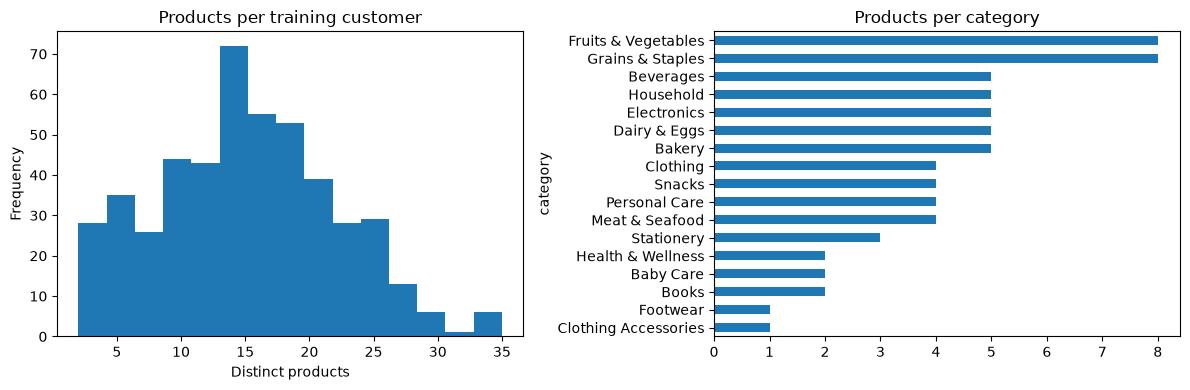

,products,customers,basket_product_occurrences
category,,,
Baby Care,2,183,236
Bakery,5,344,638
Beverages,5,320,603
Books,2,169,206
Clothing,4,288,458
Clothing Accessories,1,118,127
Dairy & Eggs,5,328,592
Electronics,5,316,589
Footwear,1,104,119


In [13]:
category_summary = train_baskets.groupby("category").agg(
    products=("product_name", "nunique"), customers=("user_id", "nunique"),
    basket_product_occurrences=("order_id", "size"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
user_degree.plot.hist(bins=15, ax=axes[0], title="Products per training customer")
axes[0].set_xlabel("Distinct products")

category_summary["products"].sort_values().plot.barh(ax=axes[1], title="Products per category")

plt.tight_layout()
plt.show()
display(category_summary)

In [14]:
popularity = train_baskets.groupby("product_name")["order_id"].nunique()

print("Training baskets per product: min =", popularity.min(), "; max =", popularity.max())

has_bought = np.zeros((n_users, n_items), dtype=np.int64)
has_bought[train_edges["user_idx"], train_edges["item_idx"]] = 1
reachable = (has_bought @ has_bought.T @ has_bought) > 0

print(f"Mean products reachable in 3 hops: {reachable.sum(axis=1).mean():.1f} / {n_items}")

Training baskets per product: min = 97 ; max = 140
Mean products reachable in 3 hops: 68.0 / 68


**Interpretation:** there is one connected training component, no isolated nodes, about 15 products per customer and 106 customers per product. Density is about 22.2% of possible customer-product links. The graph supports message passing and is small enough to train on a CPU.

There are 17 categories with **1-8 products each**. All are represented in training, but some are very narrow. Categories give a useful, simple description; they do not create 17 independent training datasets. Products in the same category need behavioural information or learned IDs to be distinguished.

Every customer can reach all 68 products in three hops. This suggests rapid mixing of information and motivates starting with two layers. It does **not** by itself prove over-smoothing (that would require examining learned embeddings).

## 7. Is this enough for a GNN? Build the future targets

There is **no universal minimum of 1,000 nodes, five neighbours or a particular category count** that makes a GNN valid or successful.

| Prerequisite or check | What it establishes here |
|---|---|
| Consistent identities and meaningful edges | We can construct a customer-product purchase graph |
| Neighbours and returning customers | There is training history to aggregate for most future customers |
| Features available before prediction | Categories and customer category profiles can be built from train |
| Enough independent future examples | There are 128 validation and 132 test customers; this is a small evaluation |
| Baseline comparison | Needed to establish whether graph learning adds predictive value |

**Answer:** this is enough for a small educational GNN experiment. It is not enough evidence to promise useful personalized recommendations. We will judge usefulness with future-month Recall@10/NDCG@10 against simple baselines, not a graph-density pass/fail rule.

Targets are unique customer-product purchases in each future month. `is_repeat=1` means bought during January-October; `0` means absent from that history. A November purchase does not change the December flag under this fixed-history experiment.

In [15]:
train_pairs = set(zip(train_edges["user_idx"], train_edges["item_idx"]))

def make_target_edges(part):
    pairs = part[["user_id", "product_name"]].drop_duplicates()
    known = pairs["user_id"].isin(user_to_idx) & pairs["product_name"].isin(item_to_idx)
    pairs = pairs.loc[known]
    out = pd.DataFrame({"user_idx": pairs["user_id"].map(user_to_idx),
                        "item_idx": pairs["product_name"].map(item_to_idx)}).astype(int)
    out["is_repeat"] = [int(pair in train_pairs) for pair in zip(out["user_idx"], out["item_idx"])]
    return out.sort_values(["user_idx", "item_idx"]).reset_index(drop=True)

val_edges = make_target_edges(val)
test_edges = make_target_edges(test)

for name, part, edges in [("Validation", val, val_edges), ("Test", test, test_edges)]:
    print(name, ":", len(edges), "target pairs;", edges["user_idx"].nunique(), "eligible customers;")
    print("  Unknown products excluded:", part.loc[~part["product_name"].isin(products), "product_name"].nunique())
    print(f"  Repeat pair share: {edges['is_repeat'].mean():.1%}")

Validation : 718 target pairs; 128 eligible customers;
  Unknown products excluded: 0
  Repeat pair share: 18.2%
Test : 774 target pairs; 132 eligible customers;
  Unknown products excluded: 0
  Repeat pair share: 23.4%


**Result:** 718 validation target pairs and 774 test target pairs remain, with no unknown products. Repeated purchases across months are intentional targets, not duplicate errors. Later, the evaluator gives every eligible customer equal weight; the pair-level repeat share above is a different summary.

The main limitations are unreliable product IDs, uncertain prices, a small 68-product catalogue, mostly one-time training links, and a small held-out customer sample. These motivate cautious comparisons. They do not prove the dataset is synthetic or that no model could improve.

## 8. Which predictors do we include?

| Input | Encoding / role | Why |
|---|---|---|
| Product category | 17 one-hot values: one 1, the rest 0 | Simple product description |
| Customer category profile | Share of training basket-product occurrences in each category | Summarizes observed interests without future leakage |
| Node type | `is_customer`: 1 for customers, 0 for products | Distinguishes the two kinds of node |
| Purchase links | `edge_index`, from train only | Supplies collaborative information |
| Purchase frequency | Optional edge `weight` | Preserves repeated-basket evidence for any model |
| Node identity | Integer maps; GCN learns an embedding per node | An ID is a lookup key, not a numeric predictor |

Exclude raw price, broken `product_id`, order IDs, quantities and time-of-day from the first model. Timestamp defines the split. `is_repeat` is an **evaluation label**, never a predictor. Future counts/categories must not be added to customer profiles.

Example: if 2 of a customer's 5 training basket-product occurrences are Bakery, their Bakery feature is `2/5 = 0.4`. The profile counts a product once per basket, matching the edge weights.

In [16]:
item_x = pd.get_dummies(item_map["category"], dtype=float)
categories = item_x.columns

user_x = pd.crosstab(train_baskets["user_id"], train_baskets["category"], normalize="index")
user_x = user_x.reindex(index=customers, columns=categories, fill_value=0)

node_features = pd.concat([user_x.reset_index(drop=True), item_x], ignore_index=True)
node_features.insert(0, "is_customer", [1] * n_users + [0] * n_items)

assert np.allclose(node_features[categories].sum(axis=1), 1)
assert np.isfinite(node_features.to_numpy()).all()
assert node_features.shape == (n_users + n_items, len(categories) + 1)

print("Feature matrix:", node_features.shape)
node_features.head().round(3)

Feature matrix: (546, 18)


,is_customer,Baby Care,Bakery,Beverages,Books,Clothing,Clothing Accessories,Dairy & Eggs,Electronics,Footwear,Fruits & Vegetables,Grains & Staples,Health & Wellness,Household,Meat & Seafood,Personal Care,Snacks,Stationery
0,1,0.000,0.000,0.167,0.167,0.000,0.000,0.333,0.000,0.000,0.000,0.167,0.000,0.000,0.167,0.000,0.000,0.000
1,1,0.091,0.000,0.000,0.000,0.091,0.091,0.000,0.091,0.000,0.182,0.091,0.000,0.000,0.091,0.091,0.091,0.091
2,1,0.000,0.057,0.057,0.029,0.029,0.029,0.057,0.229,0.029,0.057,0.114,0.029,0.029,0.057,0.029,0.114,0.057
3,1,0.000,0.000,0.000,0.000,0.250,0.000,0.000,0.125,0.000,0.250,0.000,0.000,0.125,0.000,0.125,0.125,0.000
4,1,0.050,0.050,0.050,0.000,0.000,0.000,0.150,0.150,0.000,0.150,0.150,0.050,0.050,0.050,0.000,0.100,0.000


**Result:** `x` has **546 rows × 18 columns**: 478 customer rows followed by 68 product rows, with `is_customer` followed by 17 category columns. A model transforms these observed features into learned embeddings. Features and embeddings are different things.

## 9. Validate and save the graph files

Save the six CSV files of the product-level graph to `graph_data/`, then reload them as a final check. No model training happens in this notebook.

In [17]:
for edges in [train_edges, val_edges, test_edges]:
    assert not edges.duplicated(["user_idx", "item_idx"]).any()
    assert edges["user_idx"].between(0, n_users - 1).all()
    assert edges["item_idx"].between(0, n_items - 1).all()

assert train_edges["weight"].ge(1).all()

for edges in [val_edges, test_edges]:
    expected = [int(pair in train_pairs) for pair in zip(edges["user_idx"], edges["item_idx"])]
    assert edges["is_repeat"].tolist() == expected

folder = Path("graph_data")
folder.mkdir(exist_ok=True)

for name in ["user_map", "item_map", "train_edges", "val_edges", "test_edges", "node_features"]:
    globals()[name].to_csv(folder / f"{name}.csv", index=False)
print("Saved six graph CSVs to", folder)

Saved six graph CSVs to graph_data


In [18]:
# Reload the saved files and build the model inputs; every link is stored in both directions
saved = {name: pd.read_csv(folder / f"{name}.csv") for name in ["train_edges", "node_features"]}
users = saved["train_edges"]["user_idx"].to_numpy()
items = saved["train_edges"]["item_idx"].to_numpy() + n_users      # products come after all customers
x = saved["node_features"].to_numpy(dtype=np.float32)
edge_index = np.vstack([np.concatenate([users, items]), np.concatenate([items, users])])
edge_weight = np.concatenate([saved["train_edges"]["weight"].to_numpy(dtype=np.float32)] * 2)

assert np.allclose(x, node_features.to_numpy())
assert edge_index.shape == (2, 2 * len(train_edges))

print("x:", x.shape)
print("edge_index:", edge_index.shape)
print("edge_weight:", edge_weight.shape)

x: (546, 18)
edge_index: (2, 14448)
edge_weight: (14448,)


**Saved files**

| File / array | Contents |
|---|---|
| `user_map.csv` | `user_idx`, original `user_id` |
| `item_map.csv` | `item_idx`, `product_name`, `category` |
| `train_edges.csv` | `user_idx`, local `item_idx`, `weight` (distinct baskets) |
| `val_edges.csv`, `test_edges.csv` | `user_idx`, local `item_idx`, `is_repeat` |
| `node_features.csv` / `x` | 546 × 18 values; row order is part of the contract |
| `edge_index` | 2 × 14,448 global node IDs, both directions of 7,224 links |
| `edge_weight` | 14,448 frequencies aligned with both edge directions |

Reverse edges let information flow both ways. Self-loops are not added; that is a model choice.

**Next:** `GCN_DS2_POS.ipynb` trains and evaluates the GCN. It uses the team's shared monthly customer-category snapshots, which the shared pipeline builds from the cleaned CSV saved in Section 2, rather than these product-level files.